# Tavoni et al. (2022): Python behavioral data and model fits

Load separate Gaussian and Bernoulli subject-by-condition and trial dataframes.
The model fits are **new Python reconstructions**, using the manuscript and supplied MATLAB equations.
See [python/README.md](python/README.md) for the full data dictionary, model definitions, and reproduction command.

**Data issue:** `H40P86` sequence files and behavior logs have empirical statistics near h=0.05, p=0.98, despite nominal h=0.40, p=0.86. Nominal fits are flagged and a separate empirical-statistics sensitivity analysis is provided. Do not treat this as a validated high-hazard condition.


In [36]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / "outputs").is_dir() and (root.parent / "outputs").is_dir():
    root = root.parent
out = root / "outputs"

gaussian_subject_conditions = pd.read_parquet(out / "gaussian_subject_conditions.parquet")
bernoulli_subject_conditions = pd.read_parquet(out / "bernoulli_subject_conditions.parquet")
gaussian_trials = pd.read_parquet(out / "gaussian_trials.parquet")
bernoulli_trials = pd.read_parquet(out / "bernoulli_trials.parquet")

tables = {
    "gaussian_subject_conditions": gaussian_subject_conditions,
    "bernoulli_subject_conditions": bernoulli_subject_conditions,
    "gaussian_trials": gaussian_trials,
    "bernoulli_trials": bernoulli_trials,
}
display(pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in tables.items()}).T)


,rows,columns
gaussian_subject_conditions,507,191
bernoulli_subject_conditions,217,91
gaussian_trials,202800,38
bernoulli_trials,64242,47


## Posterior density of the Gaussian source

`posterior_source_density(observations, source_values, position=None, ...)`
returns the exact Bayesian density of the **current source**, integrating over
all possible run lengths. A scalar query returns a float; an array returns
an array of the same shape. `position` is a **zero-based inclusive index**:
`position=99` uses the first 100 observations; omitting it uses the full sequence.
Later observations do not inform the posterior at an earlier position.

Pass the condition's `hazard_rate` and `noise_ratio`. The default prior is
mean 0, SD 1, matching normalized inputs to `gaussian_bayes`; raw card values
require `prior_mean=2500, prior_sd=150`. The result is a density per source
unit, not the probability of an exact point or a prediction for the next trial.

```python
# Normalized observations, like x in the exploratory cells below:
pdf = posterior_source_density(x, np.linspace(-3, 3, 501),
                               hazard_rate=hazard, noise_ratio=noiseR)
pdf_at_zero = posterior_source_density(x, 0.0, position=99,
                                       hazard_rate=hazard, noise_ratio=noiseR)
```


In [37]:
import operator
import numpy as np
from scipy.special import logsumexp
from scipy.stats import norm


def posterior_source_density(
    observations,
    source_values,
    position=None,
    *,
    hazard_rate=0.1,
    noise_ratio=1.0,
    prior_mean=0.0,
    prior_sd=1.0,
):
    """Evaluate p(mu_t = source_values | observations[:t+1]) as a density.

    Exact Gaussian change-point inference: a change occurs with probability
    hazard_rate between observations, drawing a fresh source from
    N(prior_mean, prior_sd**2). Observation SD is noise_ratio * prior_sd.
    The posterior integrates over every possible time of the last change.

    Parameters
    ----------
    observations : nonempty 1-D array-like
        Observations from one condition, in the same units as source_values.
        Include earlier training observations if they should inform the state.
    source_values : float or array-like
        Query source values. Returns a float for a scalar; otherwise an array
        of matching shape. Infinite queries return zero density.
    position : int or None, optional
        Zero-based, INCLUSIVE observation index. None uses the entire sequence;
        0 uses only its first observation; -1 uses the entire sequence.
        Other negative indices follow Python indexing. Later observations are
        ignored: this is filtering at t, rather than smoothing with future data.
    hazard_rate : float, default 0.1
        Known change probability, between 0 and 1 inclusive.
    noise_ratio : float, default 1.0
        Positive ratio R = observation SD / prior SD.
    prior_mean, prior_sd : float, default 0.0, 1.0
        Source prior parameters. Defaults use normalized coordinates, as in
        gaussian_bayes. For raw card numbers, pass the condition's prior_mean
        and prior_sd (2500 and 150 in these data).

    Returns
    -------
    float or numpy.ndarray
        Posterior density of the CURRENT latent source after the selected
        observation, per unit of source value. These are density values, so
        they need not sum to one across queries and can exceed one.
    """
    observations = np.asarray(observations, dtype=float)
    if observations.ndim != 1 or observations.size == 0:
        raise ValueError("observations must be a nonempty one-dimensional sequence")
    if position is None:
        index = observations.size - 1
    else:
        if isinstance(position, (bool, np.bool_)):
            raise TypeError("position must be an integer observation index")
        index = operator.index(position)
        if index < 0:
            index += observations.size
        if not 0 <= index < observations.size:
            raise IndexError("position is outside the observation sequence")
    prefix = observations[:index + 1]
    if not np.isfinite(prefix).all():
        raise ValueError("observations through position must all be finite")
    if not np.isfinite(hazard_rate) or not 0 <= hazard_rate <= 1:
        raise ValueError("hazard_rate must be finite and between 0 and 1")
    if not np.isfinite(noise_ratio) or noise_ratio <= 0:
        raise ValueError("noise_ratio must be finite and positive")
    if not np.isfinite(prior_mean) or not np.isfinite(prior_sd) or prior_sd <= 0:
        raise ValueError("prior_mean must be finite and prior_sd finite and positive")
    observation_variance = float(noise_ratio) ** 2
    if not np.isfinite(observation_variance) or observation_variance <= 0:
        raise ValueError("noise_ratio squared must be representable and positive")
    queries = np.asarray(source_values, dtype=float)
    if np.isnan(queries).any():
        raise ValueError("source_values must not contain NaN")

    # Filter in normalized source coordinates. Component 0 is a fresh source;
    # subsequent components continue each previous run-length hypothesis.
    means = np.array([0.0])
    variances = np.array([1.0])
    log_weights = np.array([0.0])
    log_change = np.log(hazard_rate) if hazard_rate > 0 else -np.inf
    log_continue = np.log1p(-hazard_rate) if hazard_rate < 1 else -np.inf
    for t, observation in enumerate((prefix - prior_mean) / prior_sd):
        if t:
            means = np.r_[0.0, means]
            variances = np.r_[1.0, variances]
            log_weights = np.r_[log_change, log_continue + log_weights]
        predictive_variances = variances + observation_variance
        log_weights = log_weights + norm.logpdf(
            observation, loc=means, scale=np.sqrt(predictive_variances)
        )
        log_weights -= logsumexp(log_weights)
        gain = variances / predictive_variances
        means = means + gain * (observation - means)
        variances = variances * (observation_variance / predictive_variances)

    # Evaluate the Gaussian mixture in batches to bound temporary array size.
    # Divide normalized-coordinate density by prior_sd to restore source units.
    flat_queries = queries.reshape(-1)
    result = np.empty(flat_queries.size, dtype=float)
    for start in range(0, flat_queries.size, 4096):
        z = (flat_queries[start:start + 4096] - prior_mean) / prior_sd
        component_log_densities = norm.logpdf(
            z[:, None], loc=means, scale=np.sqrt(variances)
        )
        result[start:start + 4096] = np.exp(
            logsumexp(component_log_densities + log_weights, axis=1) - np.log(prior_sd)
        )
    return float(result[0]) if queries.ndim == 0 else result.reshape(queries.shape)


Density at source=2500 after the full sequence: 0.00010379085490150407
Densities at three source values: [3.38928955e-05 1.03790855e-04 2.46899686e-04]


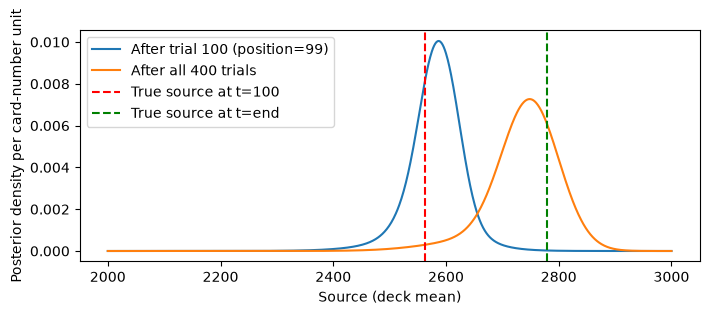

In [39]:
# Example in the original card-number units, retaining all training stimuli.
import matplotlib.pyplot as plt

posterior_example = gaussian_trials.query(
    "subject_id == 'G_varR_001' and condition_id == 'varR_h0.1_R0.8'"
).sort_values("trial_in_block")
posterior_metadata = posterior_example.iloc[0]
posterior_observations = posterior_example.stimulus.to_numpy()
posterior_settings = dict(
    hazard_rate=float(posterior_metadata.hazard_rate),
    noise_ratio=float(posterior_metadata.noise_ratio),
    prior_mean=float(posterior_metadata.prior_mean),
    prior_sd=float(posterior_metadata.prior_sd),
)
source_grid = np.linspace(2000, 3000, 1001)
posterior_full = posterior_source_density(
    posterior_observations, source_grid, **posterior_settings
)
posterior_trial_100 = posterior_source_density(
    posterior_observations, source_grid, position=99, **posterior_settings
)
print("Density at source=2500 after the full sequence:",
      posterior_source_density(posterior_observations, 2500, **posterior_settings))
print("Densities at three source values:",
      posterior_source_density(posterior_observations, [2450, 2500, 2550], **posterior_settings))

y = posterior_example.latent_state.to_numpy()

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(source_grid, posterior_trial_100, label="After trial 100 (position=99)")
ax.plot(source_grid, posterior_full, label=f"After all {len(posterior_observations)} trials")
ax.set(xlabel="Source (deck mean)", ylabel="Posterior density per card-number unit")
xlim = ax.get_xlim()
ylim = ax.get_ylim()
ax.vlines(y[100], *ylim, colors='r', linestyles='dashed', label=f'True source at t=100')
ax.vlines(y[-1], *ylim, colors='g', linestyles='dashed', label=f'True source at t=end')
ax.legend()
ax.set_xlim(xlim)
ax.set_ylim(ylim)
plt.show()


## Subject × condition summaries

Model-specific fit measures are columns such as `delta_rule__bic` and `bayesian__rmse`.
`best_model` minimizes BIC for Gaussian and SSE for Bernoulli; `best_model_by_bic` is also available.
Task performance (`subject_mse`, `accuracy`) is distinct from fit error (model output versus subject responses).

Gaussian data include 169 subjects × 3 conditions. Bernoulli includes all started blocks, including partial sessions;
filter `completed_experiment` for the 53 complete participants (212 rows).


In [2]:
display(gaussian_subject_conditions[[
    "subject_id", "condition_id", "block_index", "hazard_rate", "noise_ratio",
    "n_fit_trials", "subject_rmse", "subject_mae", "best_model", "bic_gap"
]].head(9))

bernoulli_complete_summary = bernoulli_subject_conditions.query("completed_experiment").copy()
bernoulli_complete_trials = bernoulli_trials.query("completed_experiment").copy()
display(bernoulli_complete_summary[[
    "subject_id", "condition_id", "hazard_rate", "reliability", "accuracy",
    "best_model", "nominal_statistics_suspect", "empirical_hazard_rate",
    "empirical_reliability", "sensitivity_best_model"
]].head(12))


,subject_id,condition_id,block_index,hazard_rate,noise_ratio,n_fit_trials,subject_rmse,subject_mae,best_model,bic_gap
0,G_varR_001,varR_h0.1_R0.01,2,0.1,0.01,360,122.478479,11.916667,bayesian,0.214557
1,G_varR_001,varR_h0.1_R0.8,1,0.1,0.80,359,252.100701,150.635097,evidence,2.875013
2,G_varR_001,varR_h0.1_R4,3,0.1,4.00,356,474.616850,310.064607,prior,0.984983
3,G_varR_002,varR_h0.1_R0.01,3,0.1,0.01,360,10.266991,1.588889,bayesian,5.942152
4,G_varR_002,varR_h0.1_R0.8,2,0.1,0.80,359,208.677051,104.339833,mixture_delta_rules,4.976002
5,G_varR_002,varR_h0.1_R4,1,0.1,4.00,359,282.960488,202.119777,delta_rule,5.878764
6,G_varR_003,varR_h0.1_R0.01,1,0.1,0.01,358,126.595107,10.801676,bayesian,0.071058
7,G_varR_003,varR_h0.1_R0.8,2,0.1,0.80,359,205.020428,96.913649,mixture_delta_rules,2.925303
8,G_varR_003,varR_h0.1_R4,3,0.1,4.00,360,396.369321,272.488889,mixture_delta_rules,0.180863


,subject_id,condition_id,hazard_rate,reliability,accuracy,best_model,nominal_statistics_suspect,empirical_hazard_rate,empirical_reliability,sensitivity_best_model
0,B_001,H05P57,0.05,0.57,0.487719,bayesian,False,0.073579,0.573333,NaN
1,B_001,H05P86,0.05,0.86,0.668000,bayesian,False,0.036789,0.856667,NaN
2,B_001,H05P98,0.05,0.98,0.883534,bayesian,False,0.050167,0.973333,NaN
3,B_001,H40P86,0.40,0.86,0.914530,leaky_accumulator,True,0.030100,0.980000,bayesian
4,B_002,H05P57,0.05,0.57,0.449580,leaky_accumulator,False,0.040134,0.576667,NaN
5,B_002,H05P86,0.05,0.86,0.798658,bayesian,False,0.030100,0.856667,NaN
6,B_002,H05P98,0.05,0.98,0.898649,bayesian,False,0.060201,0.990000,NaN
7,B_002,H40P86,0.40,0.86,0.900000,leaky_accumulator,True,0.053512,0.993333,bayesian
8,B_003,H05P57,0.05,0.57,0.475138,constant_prior,False,0.063545,0.623333,NaN
9,B_003,H05P86,0.05,0.86,0.686170,bayesian,False,0.056856,0.866667,NaN


## Trial-level alignment

Gaussian rows contain the displayed card (`stimulus`), the estimate (`response`), and current generative mean (`latent_state`).

Bernoulli rows represent a prediction **before the target bead is revealed**. `stimulus` is the previously revealed bead (missing at block start);
`target_bead` and `latent_state` are the target bead and its urn. All binary values use black=1, white=0.
Models process every revealed stimulus, including stimuli on trials with excluded responses. Use `included_in_fit` to reproduce fitting masks.


In [3]:
display(gaussian_trials[[
    "subject_id", "condition_id", "trial_in_block", "is_training", "stimulus",
    "response", "latent_state", "included_in_fit", "best_model_prediction"
]].head())
display(bernoulli_trials[[
    "subject_id", "condition_id", "trial_in_block", "stimulus", "response",
    "target_bead", "latent_state", "correct", "included_in_fit", "best_model_prediction"
]].head(8))


,subject_id,condition_id,trial_in_block,is_training,stimulus,response,latent_state,included_in_fit,best_model_prediction
0,G_varR_001,varR_h0.1_R0.8,1,True,2672,2500.0,2624,False,2672.0
1,G_varR_001,varR_h0.1_R0.8,2,True,2503,2600.0,2624,False,2503.0
2,G_varR_001,varR_h0.1_R0.8,3,True,2645,2545.0,2480,False,2645.0
3,G_varR_001,varR_h0.1_R0.8,4,True,2537,2687.0,2480,False,2537.0
4,G_varR_001,varR_h0.1_R0.8,5,True,2650,2684.0,2480,False,2650.0


,subject_id,condition_id,trial_in_block,stimulus,response,target_bead,latent_state,correct,included_in_fit,best_model_prediction
0,B_001,H05P57,1,NaN,0.0,0,0,True,True,0.500000
1,B_001,H05P57,2,0.0,0.0,1,0,False,True,0.491180
2,B_001,H05P57,3,1.0,1.0,0,0,False,True,0.500898
3,B_001,H05P57,4,0.0,0.0,0,0,True,True,0.491974
4,B_001,H05P57,5,0.0,0.0,0,0,True,True,0.484210
5,B_001,H05P57,6,0.0,0.0,0,0,True,True,0.477674
6,B_001,H05P57,7,0.0,0.0,1,0,False,True,0.472322
7,B_001,H05P57,8,1.0,1.0,1,0,True,True,0.482967


## All model fits and uncertainty

The eight Gaussian models are Evidence, Prior, Memoryless, Delta Rule, Sliding Window, two Delta Rules, two Sliding Windows, and exact Bayesian inference.
The three Bernoulli models are Constant Prior (a signed constant in log-prior odds), Leaky Accumulator, and Bayesian inference.

Fits are in-sample. Small BIC gaps indicate weak separation. `bic_weight` is a within-subject descriptive model weight,
not the paper's group-level variational Bayesian probability. Long fitted windows can be weakly identified;
inspect `window_exceeds_block` and `parameter_at_search_boundary`.


In [4]:
gaussian_model_fits = pd.read_parquet(out / "gaussian_model_fits.parquet")
bernoulli_model_fits = pd.read_parquet(out / "bernoulli_model_fits.parquet")
example = gaussian_subject_conditions.iloc[0]
example_fits = gaussian_model_fits.query(
    "subject_id == @example.subject_id and condition_id == @example.condition_id"
).sort_values("bic")
display(example_fits[[
    "model", "n_fit_trials", "n_parameters", "parameters_json", "rmse", "r2",
    "log_likelihood", "aic", "bic", "bic_weight", "algorithmic_complexity"
]])
display(pd.crosstab(gaussian_subject_conditions.condition_id, gaussian_subject_conditions.best_model))
display(pd.crosstab(bernoulli_complete_summary.condition_id, bernoulli_complete_summary.best_model))


,model,n_fit_trials,n_parameters,parameters_json,rmse,r2,log_likelihood,aic,bic,bic_weight,algorithmic_complexity
2,bayesian,360,1,[],122.545377,0.596267,-2241.871170,4485.742340,4489.628444,2.768460e-01,inf
0,evidence,360,1,[],122.581900,0.596027,-2241.978448,4485.956896,4489.843000,2.486840e-01,0.0
5,sliding_window,360,2,[1.2582357631728054],121.636491,0.602234,-2239.191197,4482.382394,4490.154603,2.128062e-01,20.0
4,delta_rule,360,2,[0.8028671526432742],121.649530,0.602149,-2239.229787,4482.459575,4490.231783,2.047505e-01,9.0
7,mixture_sliding_windows,360,3,"[1.399929101694959, 30214.669802469816]",121.390972,0.603838,-2238.463817,4482.927633,4494.585945,2.321296e-02,30361.0
6,mixture_delta_rules,360,3,"[0.7484034676360967, 5.7863769331589765e-11]",121.456868,0.603408,-2238.659185,4483.318369,4494.976681,1.909340e-02,129.0
3,memoryless,360,2,[0.9803296488714085],122.545008,0.596270,-2241.870087,4487.740174,4495.512382,1.460688e-02,8.0
1,prior,360,1,[],193.594988,-0.007600,-2406.494455,4814.988911,4818.875015,8.856331e-73,2.0


best_model,bayesian,delta_rule,evidence,memoryless,mixture_delta_rules,mixture_sliding_windows,prior,sliding_window
condition_id,,,,,,,,
varR_h0.1_R0.01,33,12,14,5,2,7,4,8
varR_h0.1_R0.8,10,7,21,10,7,14,4,12
varR_h0.1_R4,4,16,17,13,3,3,12,17
varh_h0.08_R1,9,12,22,10,9,4,4,14
varh_h0.38_R1,11,12,26,17,4,1,6,7
varh_h0.8_R1,11,9,33,18,0,0,5,8


best_model,bayesian,constant_prior,leaky_accumulator
condition_id,,,
H05P57,18,11,24
H05P86,51,1,1
H05P98,36,14,3
H40P86,1,0,52


## Reproducibly selected example subjects

Three subjects per experiment were sampled with seed 20261107. Gaussian panels show the first 120 valid test trials.
Bernoulli panels show 20-trial rolling means; the gray line is the nominal target P(black), which is suspect in H40P86.
The third plot compares nominal and empirical-statistics model predictions for that flagged condition.


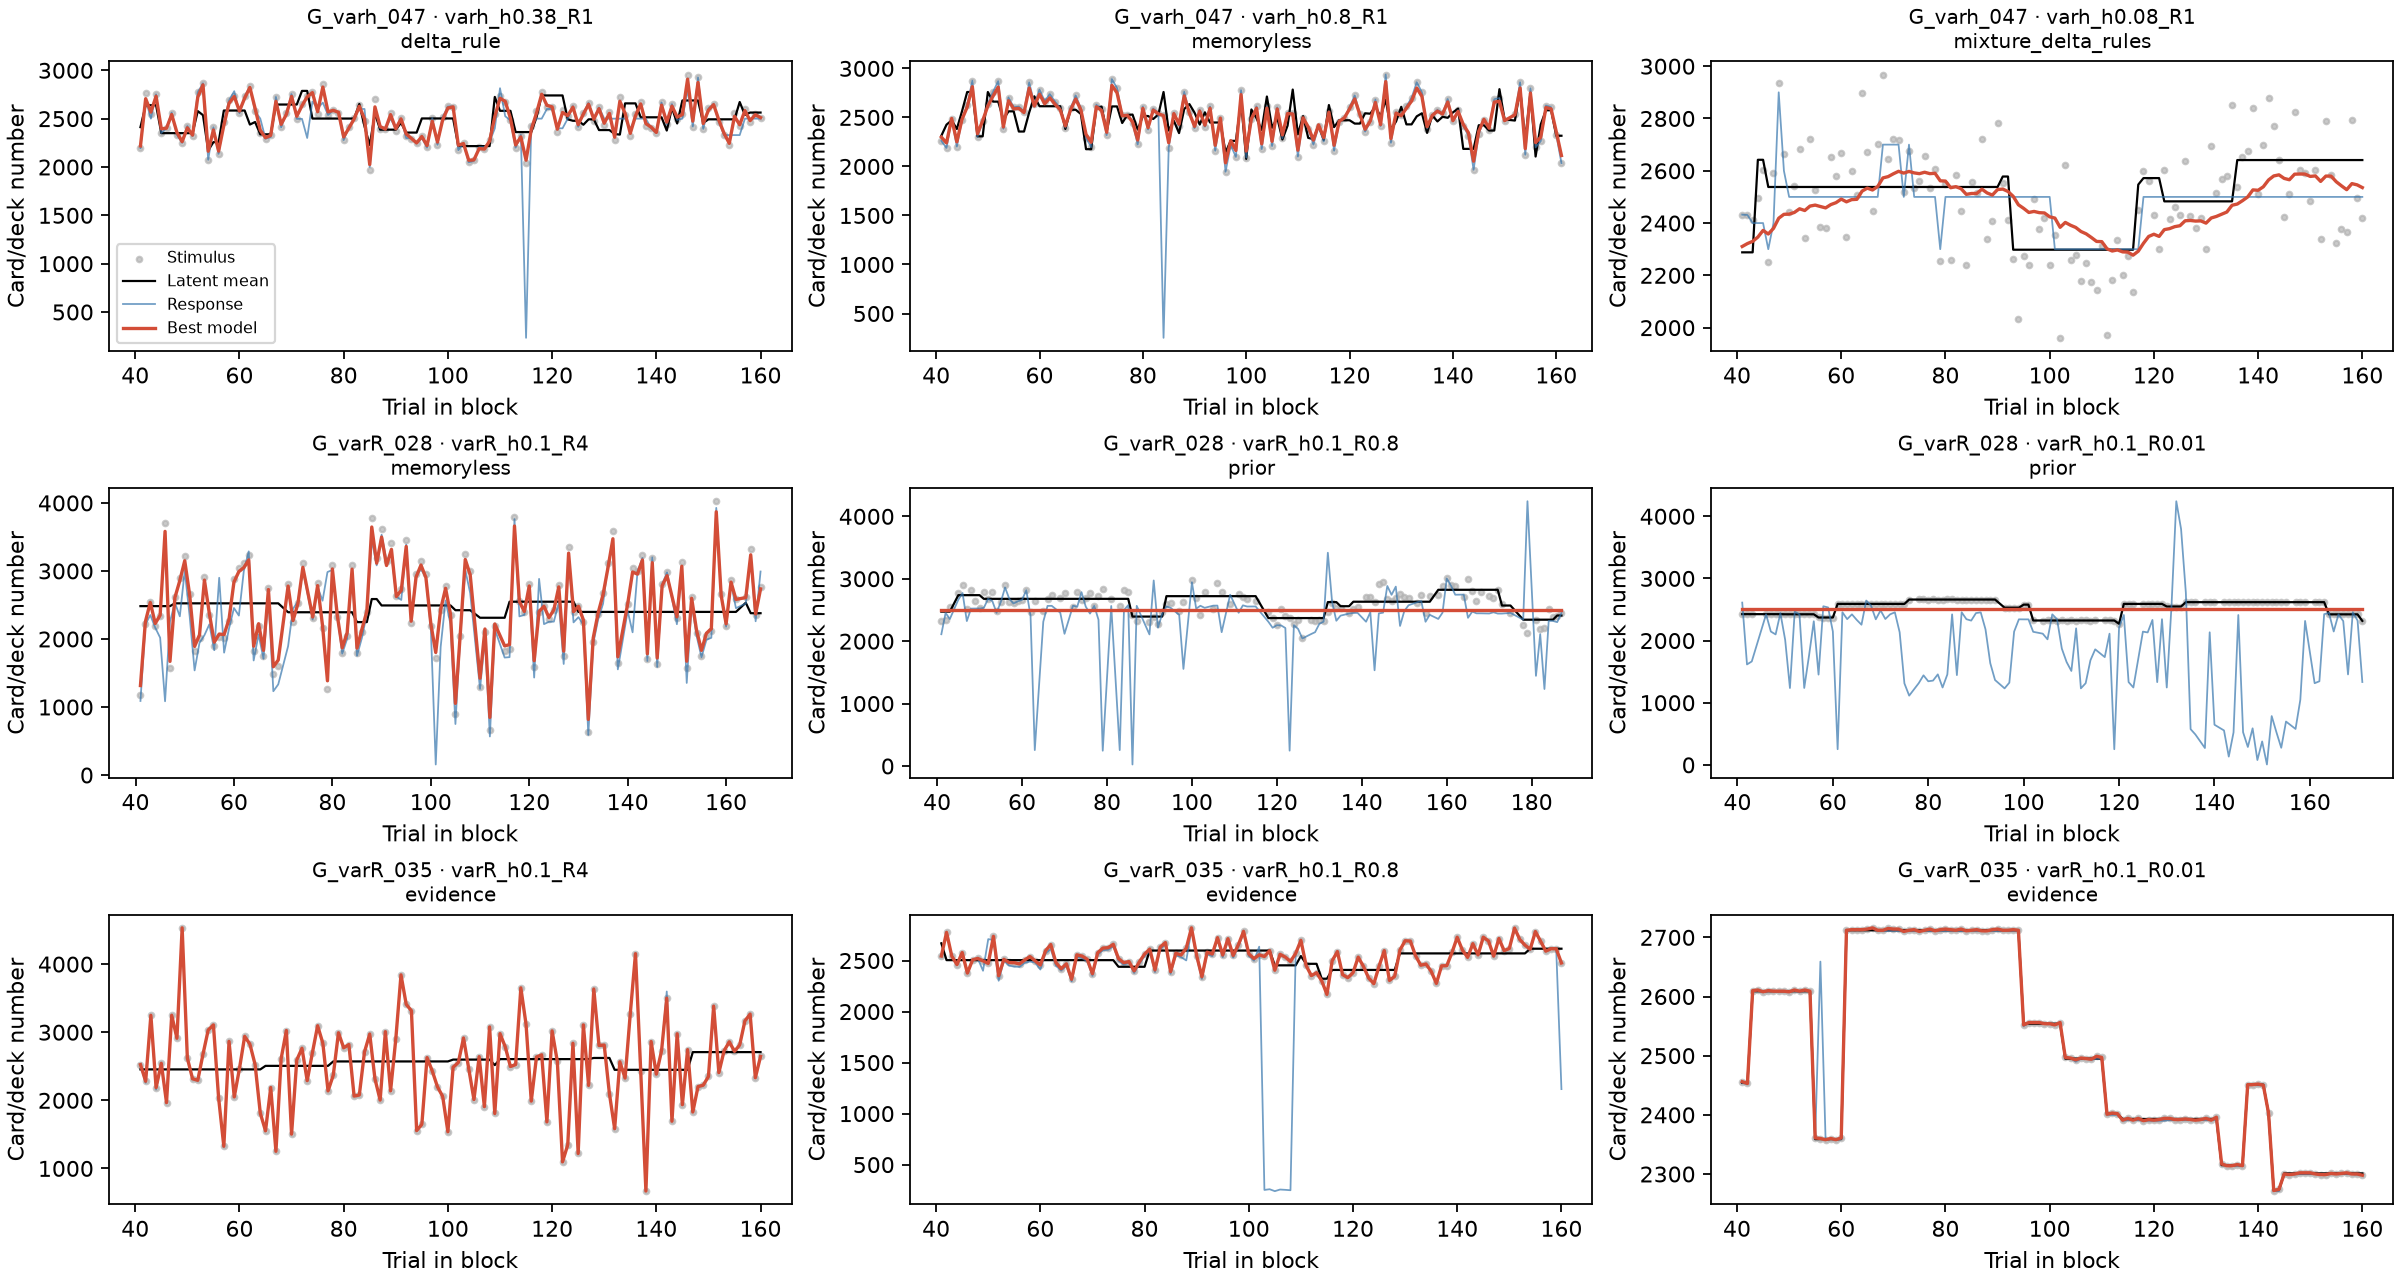

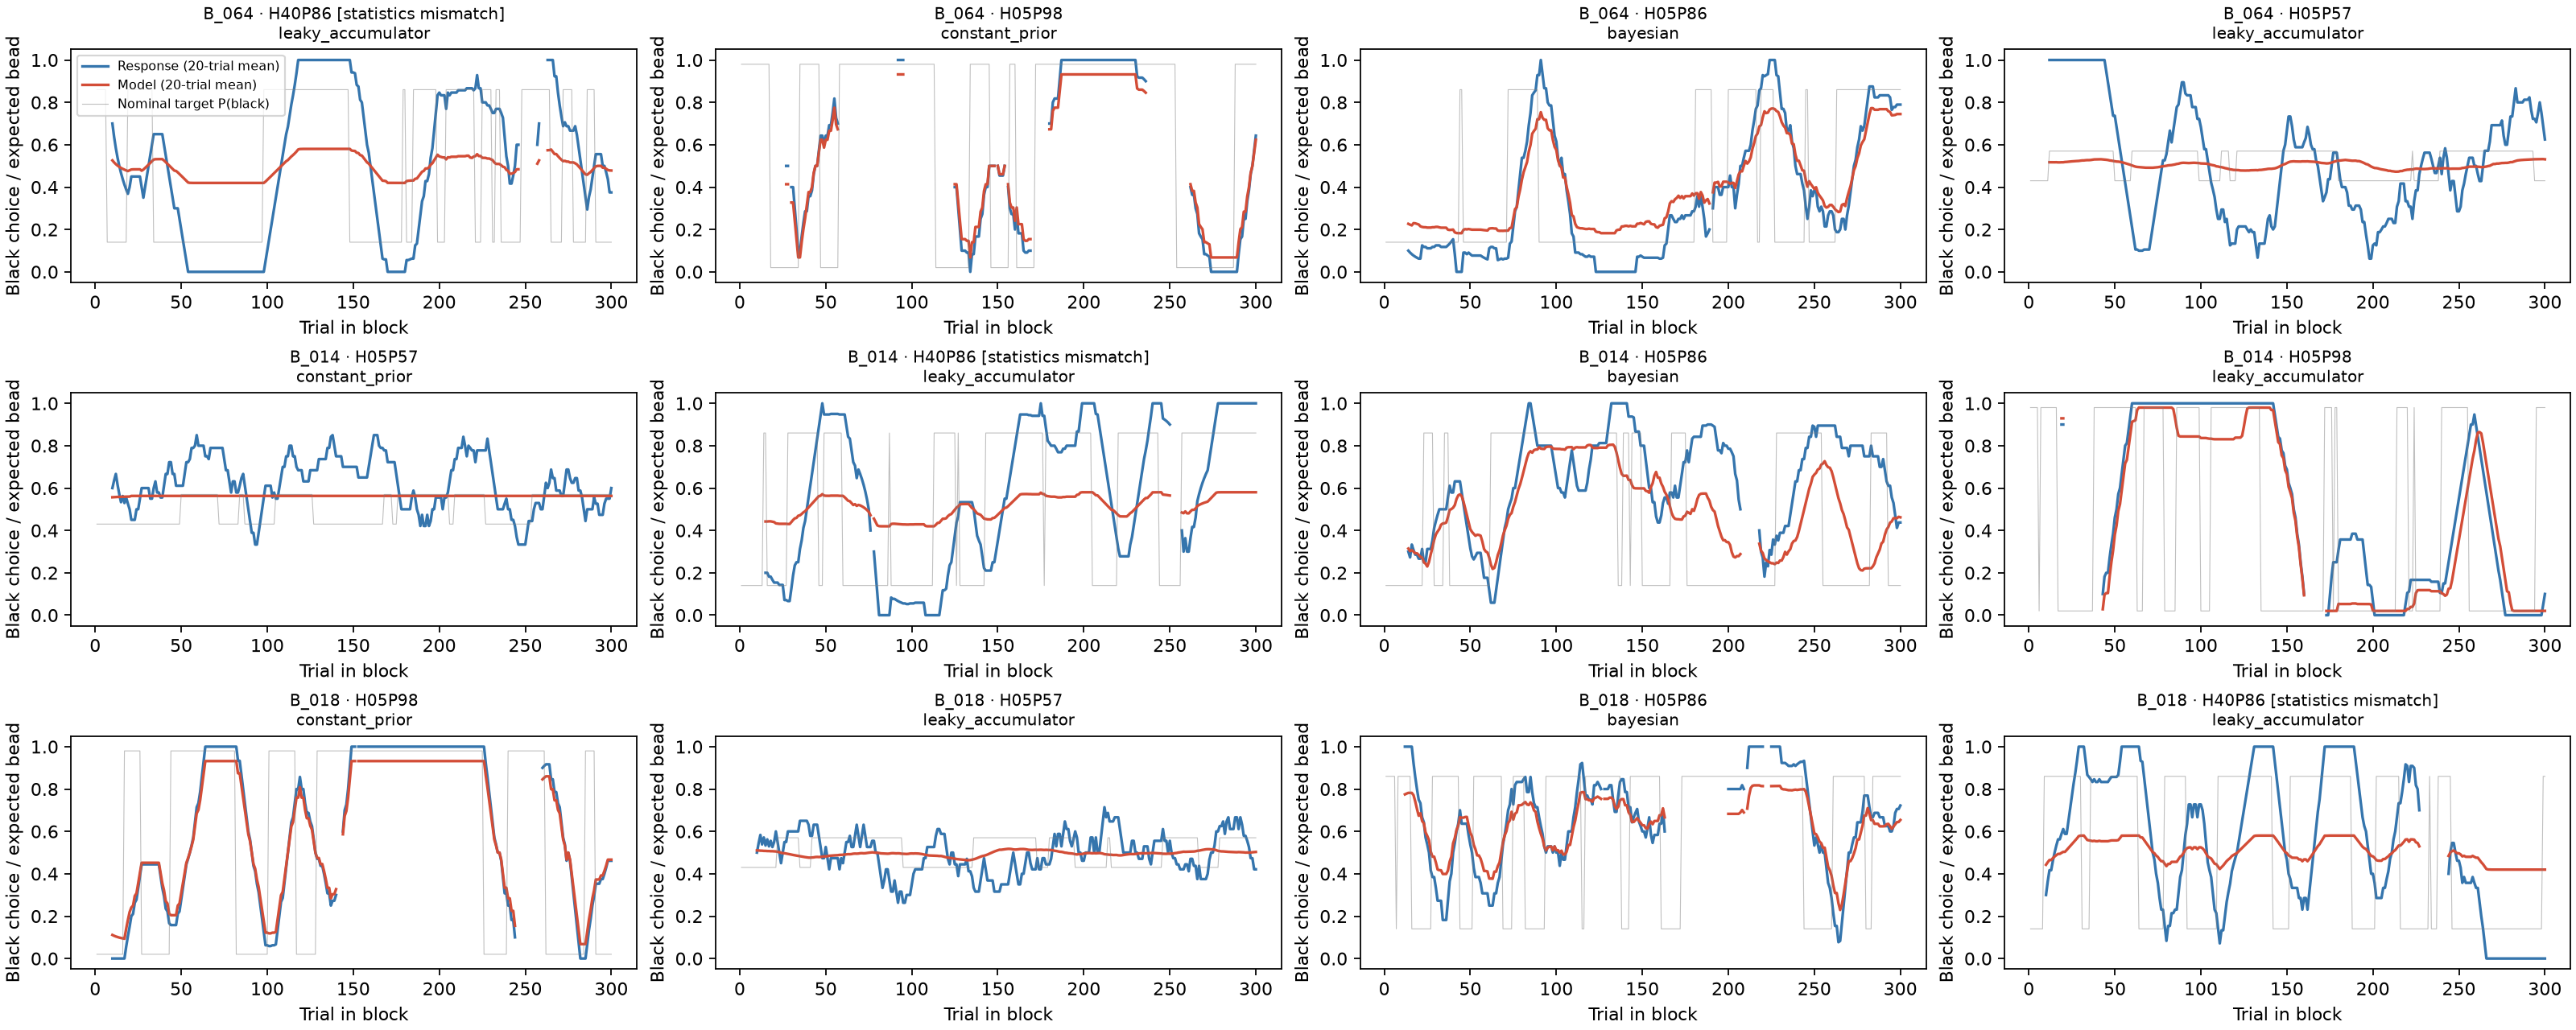

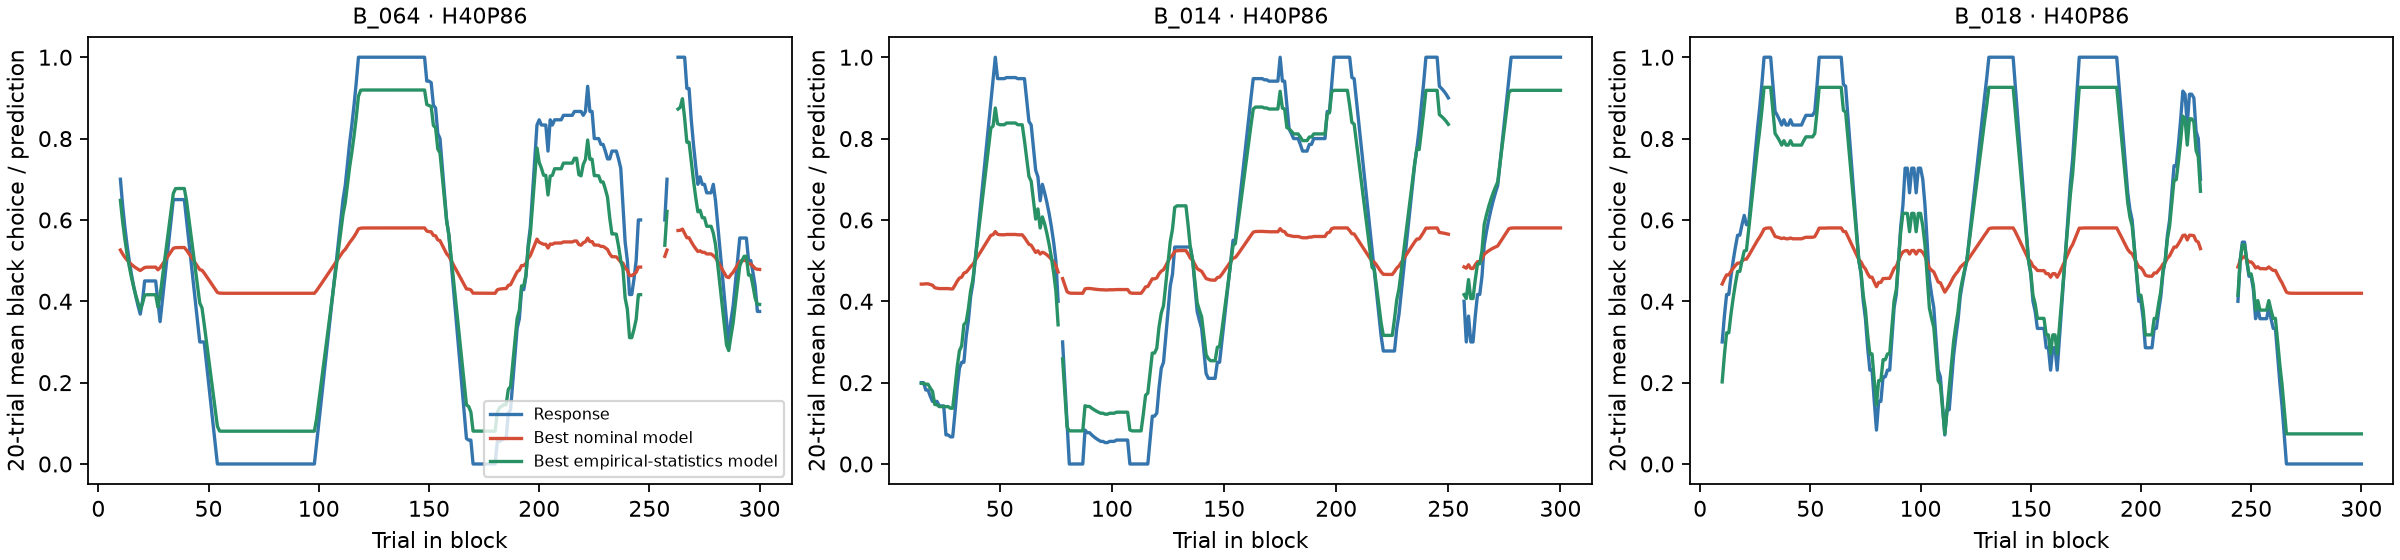

In [5]:
display(Image(filename=str(out / "gaussian_example_subjects.png")))
display(Image(filename=str(out / "bernoulli_example_subjects.png")))
display(Image(filename=str(out / "bernoulli_statistics_sensitivity.png")))


## Generative-statistics discrepancy and sensitivity

The audit uses all 500 rows in each supplied sequence; subject-condition empirical statistics use the presented block.
The sensitivity analysis estimates h and p from the supplied sequence, not from subject choices, and does not silently replace nominal values.


In [6]:
stimulus_audit = pd.read_parquet(out / "bernoulli_stimulus_audit.parquet")
display(stimulus_audit.groupby("condition_id")[[
    "nominal_hazard_rate", "nominal_reliability", "empirical_hazard_rate", "empirical_reliability"
]].mean())
sensitivity = pd.read_parquet(out / "bernoulli_statistics_sensitivity.parquet")
flagged = bernoulli_complete_summary.query("nominal_statistics_suspect")
display(pd.crosstab(flagged.best_model, flagged.sensitivity_best_model))

# Optional subset for analyses relying on trustworthy nominal condition labels.
bernoulli_unflagged_summary = bernoulli_complete_summary.query("not nominal_statistics_suspect").copy()
bernoulli_unflagged_trials = bernoulli_complete_trials.query("not nominal_statistics_suspect").copy()


,nominal_hazard_rate,nominal_reliability,empirical_hazard_rate,empirical_reliability
condition_id,,,,
H05P57,0.05,0.57,0.051122,0.57214
H05P86,0.05,0.86,0.051483,0.85762
H05P98,0.05,0.98,0.050922,0.97970
H40P86,0.40,0.86,0.051283,0.98024


sensitivity_best_model,bayesian,constant_prior,leaky_accumulator
best_model,,,
bayesian,0,0,1
leaky_accumulator,34,18,0


## Sanity checks and provenance

The pipeline checks trial identities, completion counts, training/exclusion masks, feedback/sequence alignment,
model nesting, optimizer status, recomputed fit scores, and normalized model weights. Independent tests verify
reference equations, causality, limiting cases, and synthetic parameter recovery (`.venv/bin/python -m pytest -q`).


In [7]:
report = json.loads((out / "sanity_checks.json").read_text())
display(pd.DataFrame(report["checks"]))
assert report["all_checks_passed"]
for warning in report["warnings"]:
    print("•", warning)

# Recompute one example's model SSE directly from exported trial predictions.
sid, condition = example.subject_id, example.condition_id
example_trials = gaussian_trials.query(
    "subject_id == @sid and condition_id == @condition and included_in_fit"
)
for _, fit in example_fits.iterrows():
    sse = ((example_trials.response - example_trials[f"prediction__{fit.model}"]) ** 2).sum()
    assert np.isclose(sse, fit.sse)

provenance = json.loads((out / "provenance.json").read_text())
display(provenance)


,check,passed,details
0,gaussian_unique_trial_keys,True,
1,gaussian_finite_stimuli_and_latents,True,
2,gaussian_chronological_blocks,True,
3,bernoulli_unique_trial_keys,True,
4,bernoulli_finite_stimuli_and_latents,True,
5,bernoulli_chronological_blocks,True,
6,gaussian_169_subjects_507_blocks,True,
7,gaussian_400_trials_40_training,True,
8,gaussian_three_conditions_per_subject,True,
9,bernoulli_53_complete_subjects,True,53 complete; 69 subject files


• H40P86 archive has realized h≈0.05,p≈0.98, inconsistent with nominal h=0.40,p=0.86; nominal fits flagged, empirical-statistics sensitivity exported.
• Gaussian prior SD=150 is inferred from raw generative residuals; change via --gaussian-prior-sd for sensitivity analysis.
• Fits and model-selection metrics are in-sample; BIC weights are descriptive within-subject weights, not group variational Bayes probabilities.
• The original subject-fitting code/outputs are absent. These are new fits using the documented equations, not a claim of bitwise reproduction.
• Partial Bernoulli blocks retained but not fitted; complete blocks from partial sessions have completed_experiment=False.
• Windows exceeding the 400-trial block are weakly identified; window_exceeds_block and parameter_at_search_boundary flags accompany fits.


{'seed': 20261107,
 'gaussian_prior_sd': 150,
 'python': '3.13.5 (main, Aug 10 2026, 12:06:59) [GCC 14.2.0]',
 'packages': {'numpy': '2.5.4',
  'scipy': '1.18.1',
  'pandas': '3.1.1',
  'numba': '0.68.1',
  'matplotlib': '3.11.2',
  'pyarrow': '26.0.1'},
 'source_sha256': {'data/Gaussian_task.tar.gz': '81a35a7f05a9c6b55296e943cb6811d00d1ae5966b147505f2fe0ab5d247e50d',
  'data/Bernoulli_task.tar.gz': 'e936b0c3d340d340e4dadae4f74f69e978b914abaac2db50b446a9d174df8d85'},
 'model_code_sha256': 'c13abaabbbad81f04fbb20a6e865d6c2c4dec712a075cac3cf7761ca99fcda86',
 'python_source_sha256': {'__init__.py': '90cc8a51f7a427bc997ab24dc7234b29faee083736a00a64fb5aaf8f49792993',
  'data.py': '838019317467506865dcf90f527b09d973a98fe83ed131cdf75cfcd16658925d',
  'models.py': 'c13abaabbbad81f04fbb20a6e865d6c2c4dec712a075cac3cf7761ca99fcda86',
  'pipeline.py': '40e42e6dd18601ae395849750555c32ca37aed13fde545d945caf51e7c6b5b9d'},
 'gaussian_models': ['evidence',
  'prior',
  'memoryless',
  'delta_rule',
  '

## Rerun or extend the Python analysis

```bash
PYTHONPATH=python OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 \
  .venv/bin/python -m mhi.pipeline --workers 4
```

Import from `python/mhi/data.py` to rebuild trial tables or `python/mhi/models.py` to simulate and fit models.
`python/README.md` documents startup, parameter bounds, response scales, partial-session handling, and limitations.
The supplied supplementary Kalman and HGF models, integration-kernel/adaptivity analyses, and group-level model probabilities are not part of this export.


In [8]:
gaussian_trials

,subject_id,source_subject_id,task,cohort,condition_id,block_index,trial_in_block,is_training,stimulus,response,...,prediction__evidence,prediction__prior,prediction__memoryless,prediction__delta_rule,prediction__sliding_window,prediction__mixture_delta_rules,prediction__mixture_sliding_windows,prediction__bayesian,best_model,best_model_prediction
0,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,1,True,2672,2500.0,...,2672.0,2500.0,2653.763818,2653.658321,2603.243035,2653.658321,2603.243035,2604.878049,evidence,2672.000000
1,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,2,True,2503,2600.0,...,2503.0,2500.0,2502.681927,2519.065852,2504.482173,2519.065852,2504.482173,2559.892289,evidence,2503.000000
2,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,3,True,2645,2545.0,...,2645.0,2500.0,2629.626474,2631.570676,2587.083048,2631.570676,2587.083048,2585.836961,evidence,2645.000000
3,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,4,True,2537,2687.0,...,2537.0,2500.0,2533.077100,2547.084796,2524.469759,2547.084796,2524.469759,2570.669979,evidence,2537.000000
4,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,5,True,2650,2684.0,...,2650.0,2500.0,2634.096352,2639.025363,2590.614348,2639.025363,2590.614348,2588.113524,evidence,2650.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202795,G_varh_084,AZMOA8ONG0D2U:3YGXWBAF71DWTQRM91LA6TCRINLC4L,gaussian_estimation,varh,varh_h0.08_R1,3,396,False,2780,2800.0,...,2780.0,2500.0,2716.542503,2770.412804,2640.000000,2766.955251,2640.000000,2550.837624,memoryless,2716.542503
202796,G_varh_084,AZMOA8ONG0D2U:3YGXWBAF71DWTQRM91LA6TCRINLC4L,gaussian_estimation,varh,varh_h0.08_R1,3,397,False,2552,2400.0,...,2552.0,2500.0,2540.215036,2560.227910,2526.000000,2560.136472,2526.000000,2545.155672,memoryless,2540.215036
202797,G_varh_084,AZMOA8ONG0D2U:3YGXWBAF71DWTQRM91LA6TCRINLC4L,gaussian_estimation,varh,varh_h0.08_R1,3,398,False,2456,2500.0,...,2456.0,2500.0,2465.971892,2459.926408,2478.000000,2468.059502,2478.000000,2519.675768,memoryless,2465.971892
202798,G_varh_084,AZMOA8ONG0D2U:3YGXWBAF71DWTQRM91LA6TCRINLC4L,gaussian_estimation,varh,varh_h0.08_R1,3,399,False,2237,2400.0,...,2237.0,2500.0,2296.604721,2245.397943,2368.500000,2245.965165,2368.500000,2451.919710,memoryless,2296.604721


In [9]:
# import from python/mhi/models.py
from python.mhi.models import gaussian_bayes


In [14]:
conds = (gaussian_trials['subject_id']=='G_varR_001') & (~gaussian_trials['is_training']) & (gaussian_trials['condition_id']=='varR_h0.1_R0.8')
gaussian_trials[conds]

,subject_id,source_subject_id,task,cohort,condition_id,block_index,trial_in_block,is_training,stimulus,response,...,prediction__evidence,prediction__prior,prediction__memoryless,prediction__delta_rule,prediction__sliding_window,prediction__mixture_delta_rules,prediction__mixture_sliding_windows,prediction__bayesian,best_model,best_model_prediction
40,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,41,False,2392,2641.0,...,2392.0,2500.0,2403.450626,2430.118415,2440.021365,2430.118415,2440.021365,2477.492764,evidence,2392.0
41,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,42,False,2684,2541.0,...,2684.0,2500.0,2664.491526,2656.926660,2608.762353,2656.926660,2608.762353,2559.098306,evidence,2684.0
42,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,43,False,2728,2685.0,...,2728.0,2500.0,2703.826456,2720.420905,2639.725545,2720.420905,2639.725545,2623.351488,evidence,2728.0
43,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,44,False,2707,2745.0,...,2707.0,2500.0,2685.052966,2708.431174,2627.806236,2708.431174,2627.806236,2645.394702,evidence,2707.0
44,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,45,False,2863,2634.0,...,2863.0,2500.0,2824.513173,2846.517141,2721.117885,2846.517141,2721.117885,2692.160620,evidence,2863.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,396,False,2878,2845.0,...,2878.0,2500.0,2837.922808,2806.618552,2722.108549,2806.618552,2722.108549,2728.435920,evidence,2878.0
396,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,397,False,2789,2765.0,...,2789.0,2500.0,2758.358972,2790.878801,2679.365203,2790.878801,2679.365203,2750.255122,evidence,2789.0
397,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,398,False,2866,2896.0,...,2866.0,2500.0,2827.195100,2857.989251,2724.196988,2857.989251,2724.196988,2782.046077,evidence,2866.0
398,G_varR_001,A1601UNFFAAQOI:3IXQG4FA2UUEGR5SCWL6CHHPK5UB9O,gaussian_estimation,varR,varR_h0.1_R0.8,1,399,False,2659,2614.0,...,2659.0,2500.0,2642.142134,2680.219749,2601.145600,2680.219749,2601.145600,2742.591742,evidence,2659.0


In [33]:
prior_mean = gaussian_trials.loc[conds, 'prior_mean'].iloc[0]
prior_sd = gaussian_trials.loc[conds, 'prior_sd'].iloc[0]
hazard = gaussian_trials.loc[conds, 'hazard_rate'].iloc[0]
noiseR = gaussian_trials.loc[conds, 'noise_ratio'].iloc[0]
x = (gaussian_trials.loc[conds,'stimulus'].to_numpy() - prior_mean) / prior_sd
y = (gaussian_trials.loc[conds,'latent_state'].to_numpy() - prior_mean) / prior_sd
r = (gaussian_trials.loc[conds,'response'].to_numpy() - prior_mean) / prior_sd

(-3.635, 3.735)

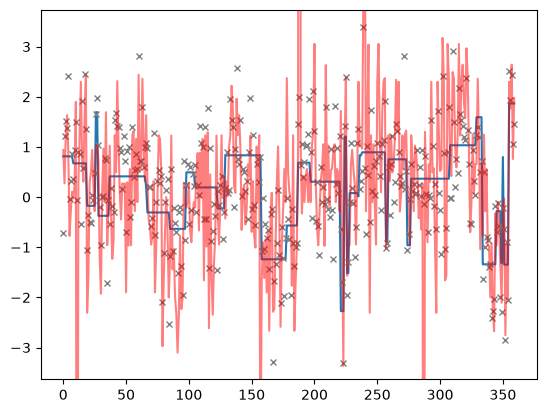

In [32]:
import matplotlib.pyplot as plt

plt.plot(np.arange(len(y)),y)
plt.plot(np.arange(len(x)), x,'x',color='gray',markersize=4)
xlim = plt.xlim()
ylim = plt.ylim()
plt.plot(np.arange(len(r)), r,color='red',markersize=4,alpha=0.5)
plt.xlim(xlim)
plt.ylim(ylim)

In [ ]:
bayes_est = gaussian_bayes(x, hazard, noiseR)

(-3.635, 3.735)

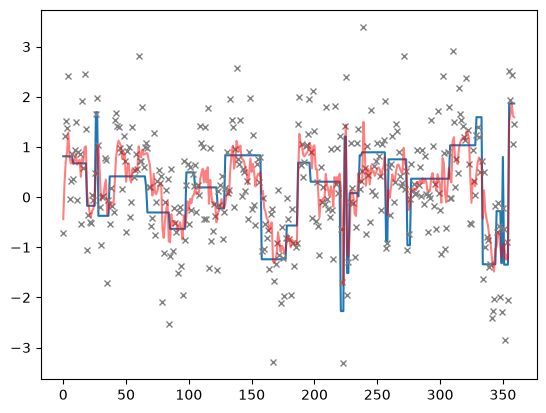

In [35]:
plt.plot(np.arange(len(y)),y)
plt.plot(np.arange(len(x)), x,'x',color='gray',markersize=4)
xlim = plt.xlim()
ylim = plt.ylim()
plt.plot(np.arange(len(bayes_est)), bayes_est,color='red',markersize=4,alpha=0.5)
plt.xlim(xlim)
plt.ylim(ylim)